In [1]:
%pip install pymupdf beautifulsoup4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 MB 19.3 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 20.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [pymupdf]m4/5 [pymupdf]ime]

[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

# Aceita execução a partir da raiz do projeto ou da pasta notebooks.
pasta_atual = Path.cwd()
raiz = pasta_atual.parent if pasta_atual.name == "notebooks" else pasta_atual

print("Raiz utilizada:", raiz)

for tipo, extensao in [("pdf", ".pdf"), ("html", ".html")]:
    pasta = raiz / "data" / "raw" / tipo

    if not pasta.is_dir():
        raise FileNotFoundError(f"Pasta não encontrada: {pasta}")

    arquivos = sorted(
        arquivo
        for arquivo in pasta.iterdir()
        if arquivo.is_file() and arquivo.suffix.lower() == extensao
    )

    print(f"\n{tipo.upper()}: {len(arquivos)} arquivos")
    for arquivo in arquivos:
        print(f"  - {arquivo.name}")

Raiz utilizada: /Users/hugofilho/Documents/projeto-pln

PDF: 4 arquivos
  - Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf
  - GradManualAlunoIbmec.pdf
  - GuiaCalouroIbmecFL.pdf
  - GuiadoAlunoIbmecFariaLima.pdf

HTML: 14 arquivos
  - 05.html
  - 06.html
  - 07.html
  - 08.html
  - 09.html
  - 10.html
  - 11.html
  - 12.html
  - 13.html
  - 14.html
  - 15.html
  - 16.html
  - 17.html
  - 18.html


In [3]:
import sys
from importlib.util import find_spec

print("Python do notebook:", sys.executable)

for modulo, pacote in [
    ("pymupdf", "PyMuPDF"),
    ("bs4", "Beautiful Soup"),
]:
    status = "disponível" if find_spec(modulo) else "não encontrado"
    print(f"{pacote}: {status}")

Python do notebook: /opt/homebrew/anaconda3/bin/python
PyMuPDF: disponível
Beautiful Soup: disponível


In [7]:
import pymupdf

arquivo_pdf = raiz / "data" / "raw" / "pdf" / "GradManualAlunoIbmec.pdf"
numero_pagina = 11  # Posição da página no PDF, contando a capa.

with pymupdf.open(arquivo_pdf) as documento:
    pagina = documento[numero_pagina - 1]
    texto = pagina.get_text()

    print("Arquivo:", arquivo_pdf.name)
    print("Total de páginas:", len(documento))
    print("Página consultada:", numero_pagina)
    print("Caracteres extraídos:", len(texto.strip()))
    print("\n--- TEXTO EXTRAÍDO ---\n")

    if texto.strip():
        print(texto)
    else:
        print("Nenhum texto extraído. Precisamos inspecionar esta página.")

Arquivo: GradManualAlunoIbmec.pdf
Total de páginas: 49
Página consultada: 11
Caracteres extraídos: 1146

--- TEXTO EXTRAÍDO ---

Campus Virtual (SIA)
O Campus Virtual ou SIA (Sistema de Informações 
Acadêmicas) é essencial durante toda sua graduação. 
Conheça os serviços e as facilidades disponíveis:
 
	
• Solicitações acadêmicas e financeiras;
	
• Consultar a biblioteca virtual;
	
• Acessar a Sala de Aula Virtual;
	
• Renovar sua matrícula;
	
• Verificar sua grade de horários, calendário  
	
acadêmico, sua frequência e notas durante o semestre;
	
• Conferir seu contrato de prestação de serviços 	
	
      	
	
educacionais.
O Campus Virtual (SIA) está disponível no endereço http://
sia.ibmec.br/sianet/logon e poderá realizar o login usando 
o e-mail do estudante ou número de matrícula, a senha é 
cadastrada no primeiro acesso (SIA – login).
Para criar sua senha, acesse o Campus Virtual (SIA), digite o número da sua 
matrícula de aluno e em seguida clique no botão “Esqueci minha senha / 

In [8]:
from IPython.display import display, HTML
from html import escape

display(HTML(
    '<pre style="white-space: pre-wrap; max-height: 500px; overflow-y: auto;">'
    + escape(texto)
    + '</pre>'
))

In [9]:
paginas_manual = []

with pymupdf.open(arquivo_pdf) as documento:
    for numero, pagina in enumerate(documento, start=1):
        texto_pagina = pagina.get_text()

        paginas_manual.append({
            "arquivo": arquivo_pdf.name,
            "pagina": numero,
            "texto": texto_pagina,
            "sem_texto": not texto_pagina.strip(),
        })

paginas_sem_texto = [
    registro["pagina"]
    for registro in paginas_manual
    if registro["sem_texto"]
]

print("Arquivo:", arquivo_pdf.name)
print("Páginas processadas:", len(paginas_manual))
print("Páginas sem texto extraível:", paginas_sem_texto)

Arquivo: GradManualAlunoIbmec.pdf
Páginas processadas: 49
Páginas sem texto extraível: [1]


In [10]:
for registro in paginas_manual:
    quantidade = len(registro["texto"].strip())

    print(
        f"Página {registro['pagina']:02d}: "
        f"{quantidade:5d} caracteres"
    )

Página 01:     0 caracteres
Página 02:  3935 caracteres
Página 03:  6970 caracteres
Página 04:  2280 caracteres
Página 05:   706 caracteres
Página 06:   319 caracteres
Página 07:   360 caracteres
Página 08:   225 caracteres
Página 09:  1135 caracteres
Página 10:    39 caracteres
Página 11:  1146 caracteres
Página 12:   869 caracteres
Página 13:  1588 caracteres
Página 14:  1888 caracteres
Página 15:    20 caracteres
Página 16:  2524 caracteres
Página 17:  2532 caracteres
Página 18:  2919 caracteres
Página 19:  1691 caracteres
Página 20:  2324 caracteres
Página 21:  2426 caracteres
Página 22:   599 caracteres
Página 23:  1760 caracteres
Página 24:  1714 caracteres
Página 25:    15 caracteres
Página 26:  2237 caracteres
Página 27:  1898 caracteres
Página 28:  1445 caracteres
Página 29:  1785 caracteres
Página 30:  1829 caracteres
Página 31:  2149 caracteres
Página 32:  1583 caracteres
Página 33:  1593 caracteres
Página 34:    25 caracteres
Página 35:  1739 caracteres
Página 36:   844 car

In [11]:
for registro in paginas_manual:
    texto = registro["texto"].strip()

    if len(texto) < 100:
        print(f"Página {registro['pagina']:02d}: {len(texto)} caracteres")
        print(repr(texto))
        print()

Página 01: 0 caracteres
''

Página 10: 39 caracteres
'Campus Virtual e \nCanais de Comunicação'

Página 15: 20 caracteres
'PROGRAMAS\nE SERVIÇOS'

Página 25: 15 caracteres
'GUIA \nACADÊMICO'

Página 34: 25 caracteres
'PROCEDIMENTOS \nACADÊMICOS'

Página 45: 16 caracteres
'GUIA \nFINANCEIRO'

Página 48: 17 caracteres
'GUIA DE\nRENOVAÇÃO'



Página 1


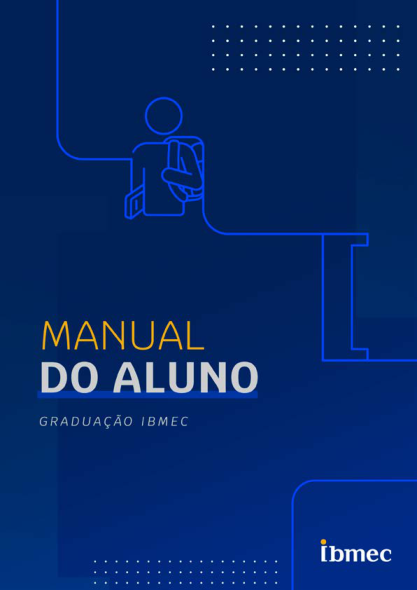

Página 10


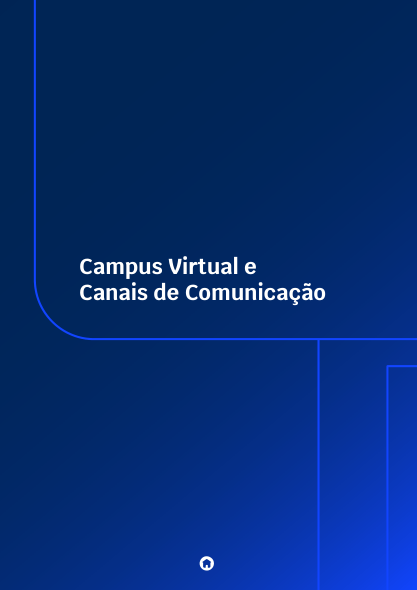

Página 15


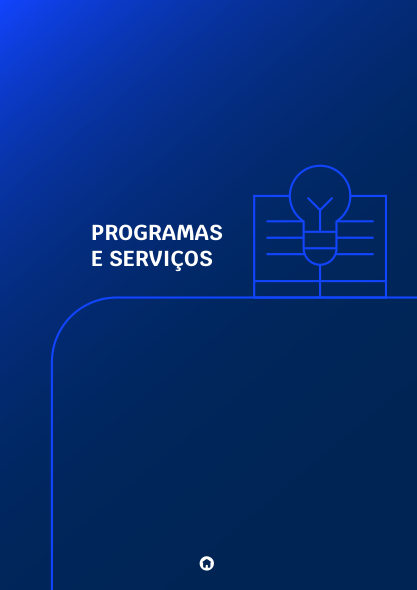

Página 25


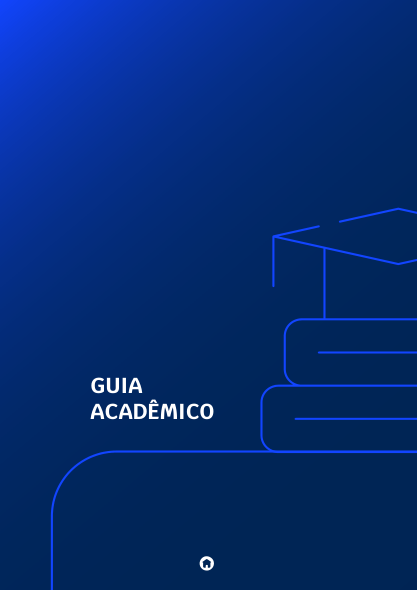

Página 34


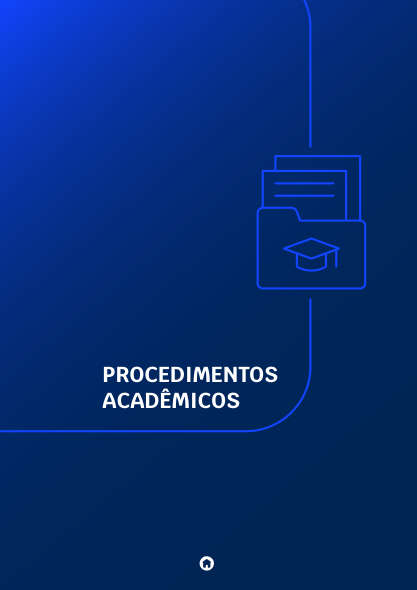

Página 45


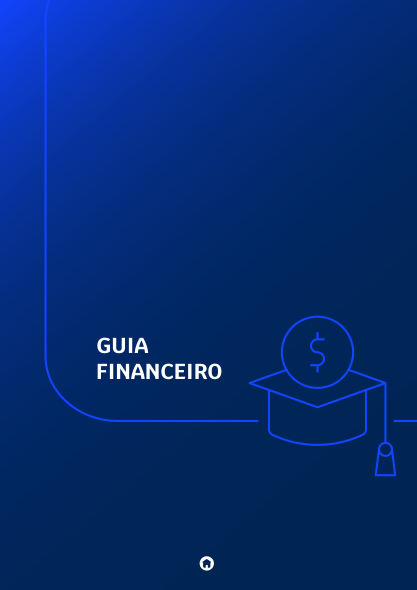

Página 48


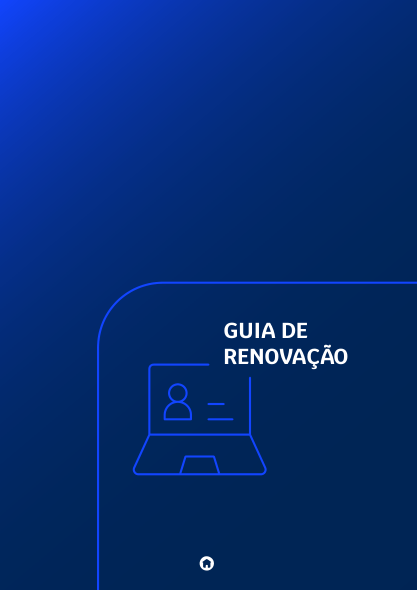

In [12]:
from IPython.display import display, Image

with pymupdf.open(arquivo_pdf) as documento:
    for registro in paginas_manual:
        if len(registro["texto"].strip()) < 100:
            numero = registro["pagina"]
            print(f"Página {numero}")

            imagem = documento[numero - 1].get_pixmap(
                matrix=pymupdf.Matrix(0.7, 0.7)
            )
            display(Image(data=imagem.tobytes("png")))

In [13]:
arquivo_guia = raiz / "data" / "raw" / "pdf" / "GuiadoAlunoIbmecFariaLima.pdf"
paginas_guia = []

with pymupdf.open(arquivo_guia) as documento:
    for numero, pagina in enumerate(documento, start=1):
        texto_pagina = pagina.get_text()

        paginas_guia.append({
            "arquivo": arquivo_guia.name,
            "pagina": numero,
            "texto": texto_pagina,
            "sem_texto": not texto_pagina.strip(),
        })

print("Arquivo:", arquivo_guia.name)
print("Páginas processadas:", len(paginas_guia))
print("Páginas com menos de 100 caracteres:")

for registro in paginas_guia:
    texto = registro["texto"].strip()

    if len(texto) < 100:
        print(f"  Página {registro['pagina']}: {len(texto)} caracteres")
        print(f"  {texto!r}")

Arquivo: GuiadoAlunoIbmecFariaLima.pdf
Páginas processadas: 12
Páginas com menos de 100 caracteres:
  Página 1: 28 caracteres
  'Fique por Dentro! \nSeu Ibmec'
  Página 7: 62 caracteres
  'Mapa do Aluno\nSalas de Estudo na Biblioteca | 1º andar\nRooftop'
  Página 8: 59 caracteres
  'Mapa do Aluno\nMegamatte | Rooftop\nVarandas | 1º ao 4º andar'


Página 1


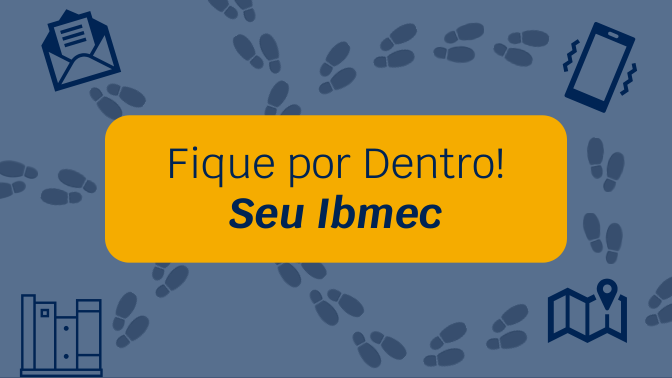

Página 7


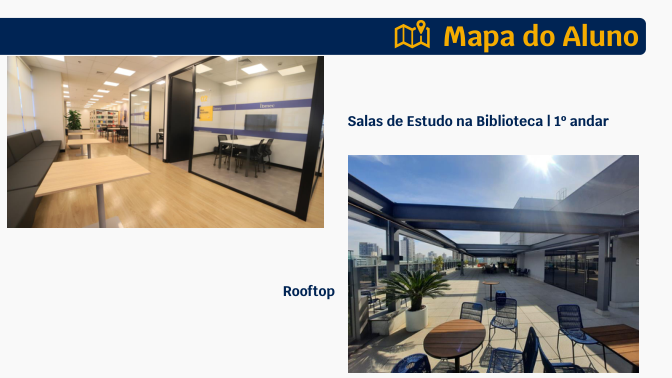

Página 8


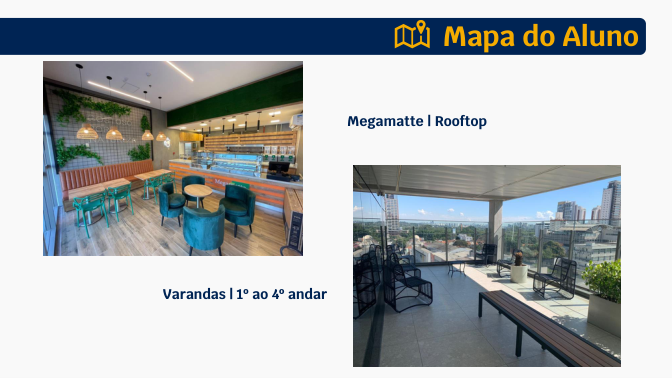

In [14]:
with pymupdf.open(arquivo_guia) as documento:
    for numero in [1, 7, 8]:
        print(f"Página {numero}")

        imagem = documento[numero - 1].get_pixmap(
            matrix=pymupdf.Matrix(0.7, 0.7)
        )
        display(Image(data=imagem.tobytes("png")))

In [16]:
numero_pagina = 4
registro = paginas_guia[numero_pagina - 1]

print("Arquivo:", registro["arquivo"])
print("Página:", registro["pagina"])

display(HTML(
    '<pre style="white-space: pre-wrap; max-height: 500px; overflow-y: auto;">'
    + escape(registro["texto"])
    + '</pre>'
))

Arquivo: GuiadoAlunoIbmecFariaLima.pdf
Página: 4


In [17]:
arquivo_calouro = raiz / "data" / "raw" / "pdf" / "GuiaCalouroIbmecFL.pdf"
paginas_calouro = []

with pymupdf.open(arquivo_calouro) as documento:
    for numero, pagina in enumerate(documento, start=1):
        texto_pagina = pagina.get_text()

        paginas_calouro.append({
            "arquivo": arquivo_calouro.name,
            "pagina": numero,
            "texto": texto_pagina,
            "sem_texto": not texto_pagina.strip(),
        })

print("Arquivo:", arquivo_calouro.name)
print("Páginas processadas:", len(paginas_calouro))
print("Páginas com menos de 100 caracteres:")

for registro in paginas_calouro:
    texto = registro["texto"].strip()

    if len(texto) < 100:
        print(f"  Página {registro['pagina']}: {len(texto)} caracteres")
        print(f"  {texto!r}")

Arquivo: GuiaCalouroIbmecFL.pdf
Páginas processadas: 49
Páginas com menos de 100 caracteres:
  Página 1: 33 caracteres
  'Guia do\nCalouro\nCampus Faria Lima'
  Página 4: 11 caracteres
  'A Faculdade'
  Página 10: 25 caracteres
  'Atendimento\nEspecializado'
  Página 20: 21 caracteres
  'Plataformas\ne Acessos'
  Página 34: 49 caracteres
  'APP Meu Ibmec\nSua vida acadêmica \nna palma da mão'
  Página 37: 21 caracteres
  'Convênios \nExclusivos'
  Página 41: 29 caracteres
  'Mais \nBenefícios e \nConteúdos'
  Página 49: 0 caracteres
  ''


Página 1


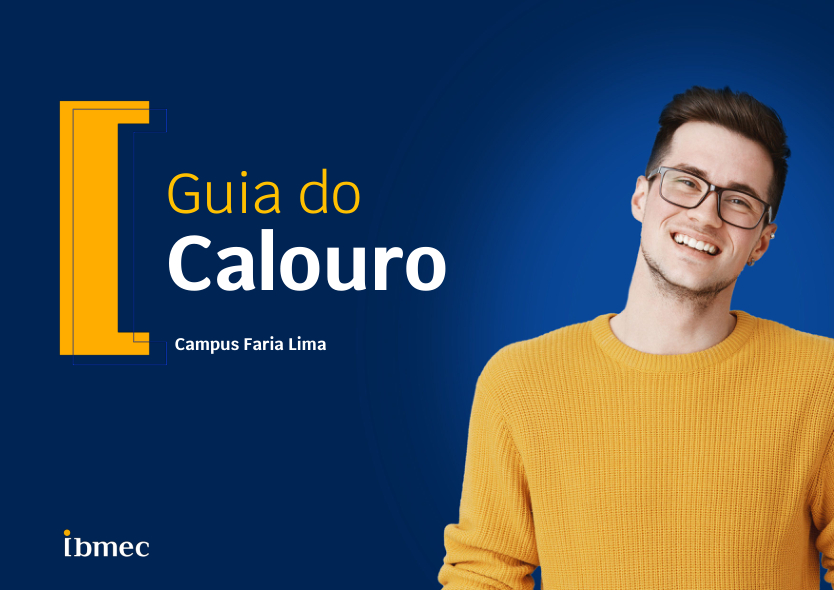

Página 4


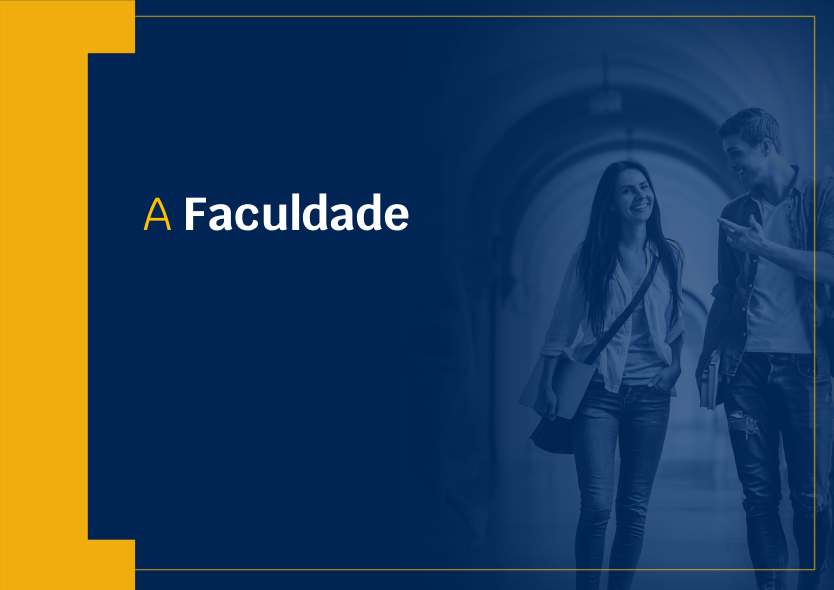

Página 10


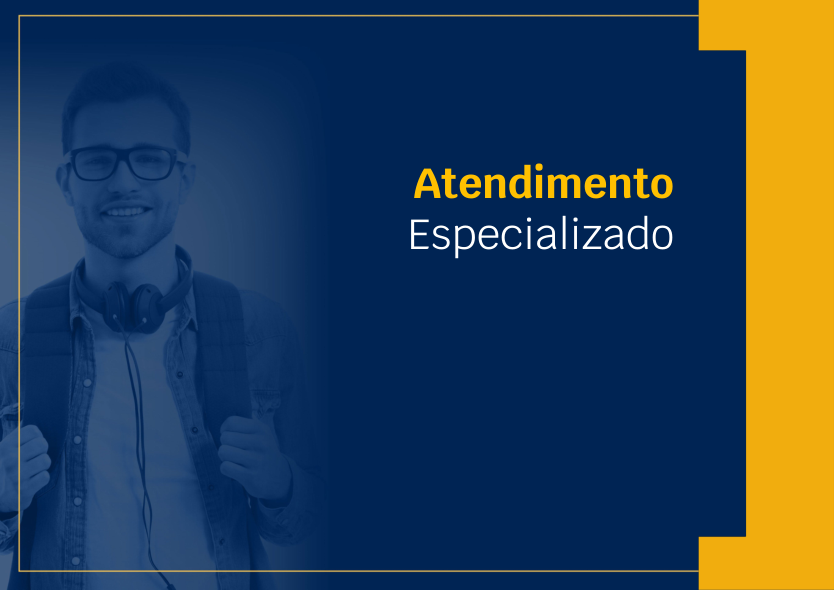

Página 20


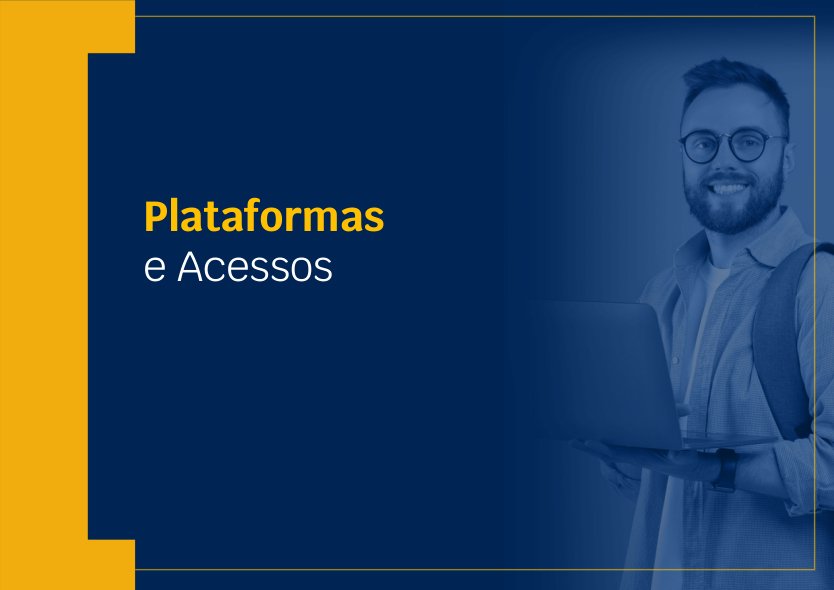

Página 34


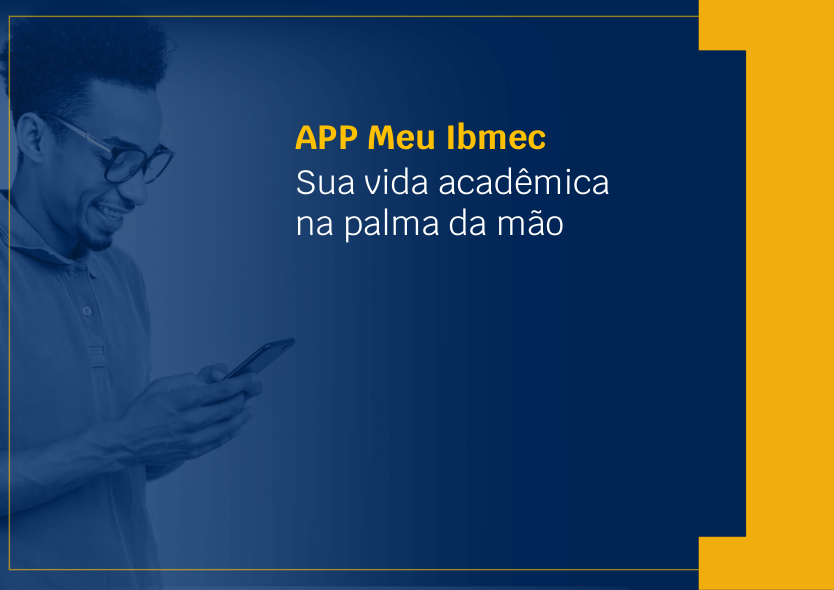

Página 37


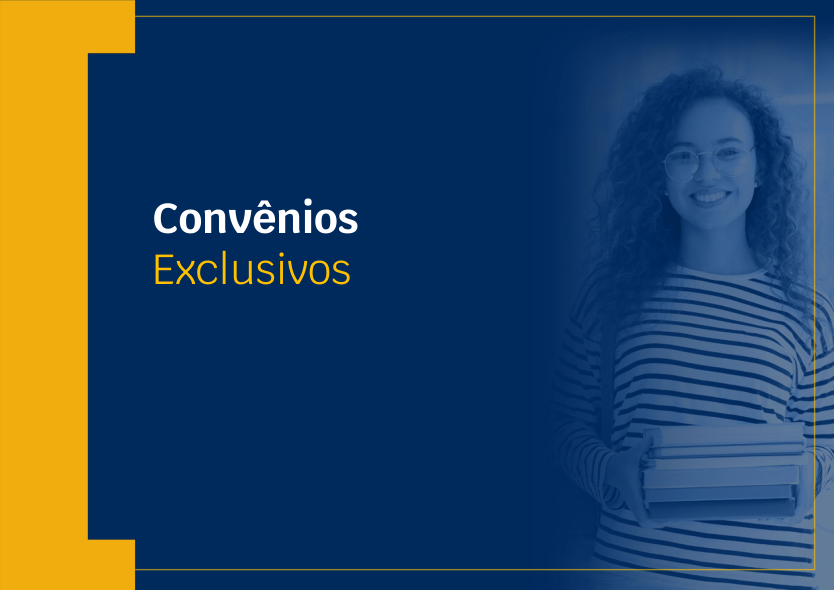

Página 41


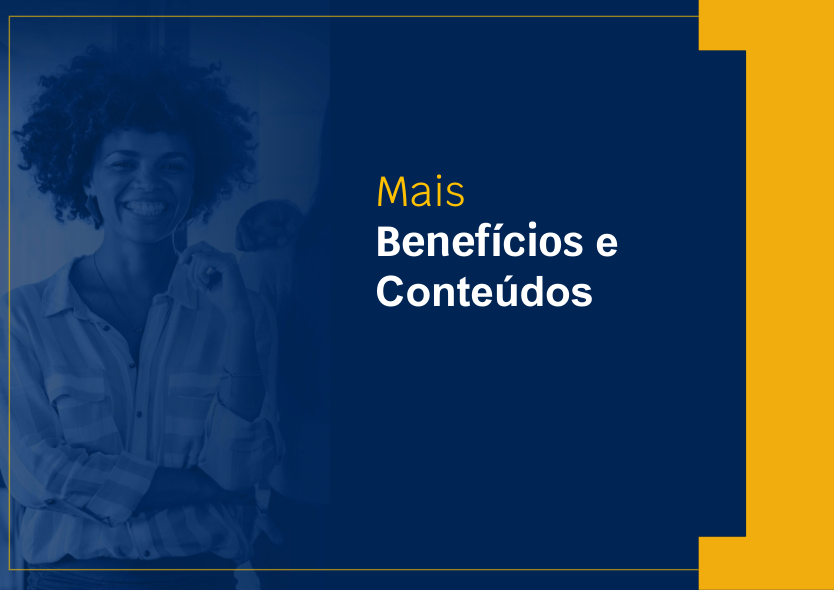

Página 49


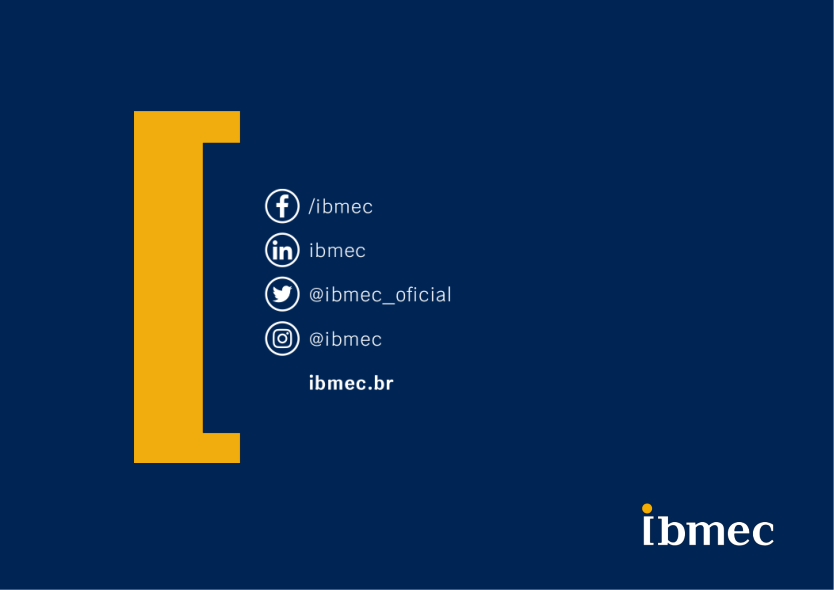

In [18]:
with pymupdf.open(arquivo_calouro) as documento:
    for registro in paginas_calouro:
        if len(registro["texto"].strip()) < 100:
            numero = registro["pagina"]
            print(f"Página {numero}")

            imagem = documento[numero - 1].get_pixmap(
                matrix=pymupdf.Matrix(0.7, 0.7)
            )
            display(Image(data=imagem.tobytes("png")))

In [19]:
numero_pagina = 5  # Troque pela página que deseja conferir.
registro = paginas_calouro[numero_pagina - 1]

print("Arquivo:", registro["arquivo"])
print("Página:", registro["pagina"])

display(HTML(
    '<pre style="white-space: pre-wrap; max-height: 500px; overflow-y: auto;">'
    + escape(registro["texto"])
    + '</pre>'
))

Arquivo: GuiaCalouroIbmecFL.pdf
Página: 5


Arquivo: Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf
Total de páginas: 1


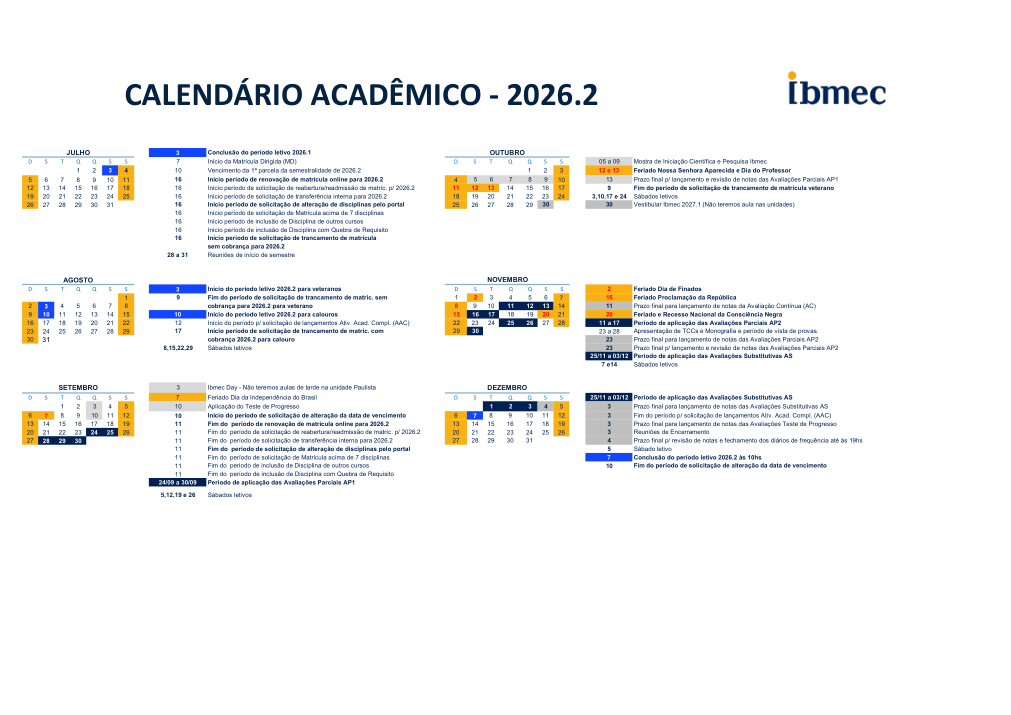

In [20]:
arquivo_calendario = (
    raiz / "data" / "raw" / "pdf"
    / "Calendario_Academico_2026_2_Ibmec_SP_v5_08310586a3.pdf"
)

with pymupdf.open(arquivo_calendario) as documento:
    print("Arquivo:", arquivo_calendario.name)
    print("Total de páginas:", len(documento))

    imagem = documento[0].get_pixmap(
        matrix=pymupdf.Matrix(1.2, 1.2)
    )
    display(Image(data=imagem.tobytes("png")))

In [21]:
with pymupdf.open(arquivo_calendario) as documento:
    texto_calendario = documento[0].get_text()

display(HTML(
    '<pre style="white-space: pre-wrap; max-height: 500px; overflow-y: auto;">'
    + escape(texto_calendario)
    + '</pre>'
))

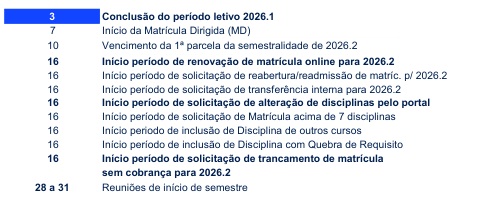

In [22]:
with pymupdf.open(arquivo_calendario) as documento:
    pagina = documento[0]
    largura = pagina.rect.width
    altura = pagina.rect.height

    # Recorte inicial: lista de eventos de julho.
    recorte_julho = pymupdf.Rect(
        largura * 0.145,  # Limite esquerdo
        altura * 0.20,    # Limite superior
        largura * 0.43,   # Limite direito
        altura * 0.375,  # Limite inferior
    )

    imagem = pagina.get_pixmap(
        matrix=pymupdf.Matrix(2, 2),
        clip=recorte_julho,
    )
    texto_julho = pagina.get_text(clip=recorte_julho)

display(Image(data=imagem.tobytes("png")))

display(HTML(
    '<pre style="white-space: pre-wrap;">'
    + escape(texto_julho)
    + '</pre>'
))

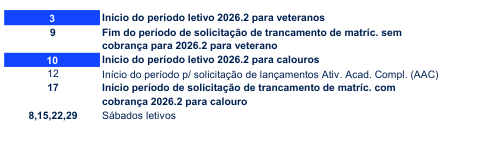

In [23]:
with pymupdf.open(arquivo_calendario) as documento:
    pagina = documento[0]
    largura = pagina.rect.width
    altura = pagina.rect.height

    recorte_agosto = pymupdf.Rect(
        largura * 0.145,
        altura * 0.39,
        largura * 0.43,
        altura * 0.515,
    )

    imagem = pagina.get_pixmap(
        matrix=pymupdf.Matrix(2, 2),
        clip=recorte_agosto,
    )
    texto_agosto = pagina.get_text(clip=recorte_agosto)

display(Image(data=imagem.tobytes("png")))

display(HTML(
    '<pre style="white-space: pre-wrap;">'
    + escape(texto_agosto)
    + '</pre>'
))

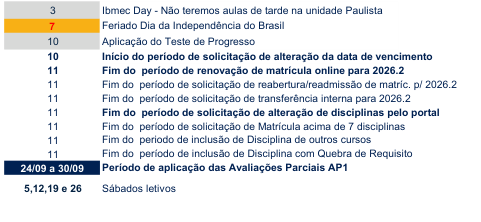

In [24]:
with pymupdf.open(arquivo_calendario) as documento:
    pagina = documento[0]
    largura = pagina.rect.width
    altura = pagina.rect.height

    recorte_setembro = pymupdf.Rect(
        largura * 0.145,
        altura * 0.535,
        largura * 0.43,
        altura * 0.72,
    )

    imagem = pagina.get_pixmap(
        matrix=pymupdf.Matrix(2, 2),
        clip=recorte_setembro,
    )
    texto_setembro = pagina.get_text(clip=recorte_setembro)

display(Image(data=imagem.tobytes("png")))

display(HTML(
    '<pre style="white-space: pre-wrap;">'
    + escape(texto_setembro)
    + '</pre>'
))

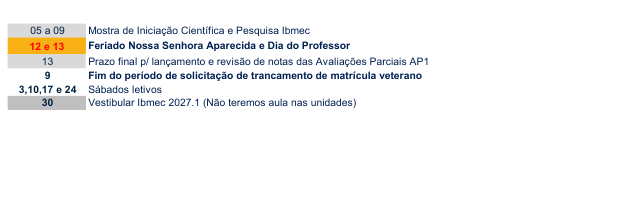

In [25]:
with pymupdf.open(arquivo_calendario) as documento:
    pagina = documento[0]
    largura = pagina.rect.width
    altura = pagina.rect.height

    recorte_outubro = pymupdf.Rect(
        largura * 0.575,
        altura * 0.20,
        largura * 0.95,
        altura * 0.375,
    )

    imagem = pagina.get_pixmap(
        matrix=pymupdf.Matrix(2, 2),
        clip=recorte_outubro,
    )
    texto_outubro = pagina.get_text(clip=recorte_outubro)

display(Image(data=imagem.tobytes("png")))

display(HTML(
    '<pre style="white-space: pre-wrap;">'
    + escape(texto_outubro)
    + '</pre>'
))

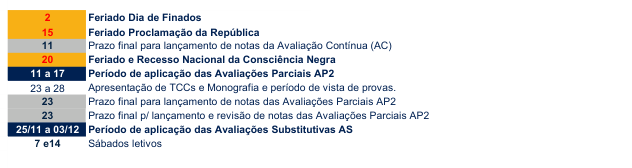

In [26]:
with pymupdf.open(arquivo_calendario) as documento:
    pagina = documento[0]
    largura = pagina.rect.width
    altura = pagina.rect.height

    recorte_novembro = pymupdf.Rect(
        largura * 0.575,
        altura * 0.39,
        largura * 0.95,
        altura * 0.53,
    )

    imagem = pagina.get_pixmap(
        matrix=pymupdf.Matrix(2, 2),
        clip=recorte_novembro,
    )
    texto_novembro = pagina.get_text(clip=recorte_novembro)

display(Image(data=imagem.tobytes("png")))

display(HTML(
    '<pre style="white-space: pre-wrap;">'
    + escape(texto_novembro)
    + '</pre>'
))

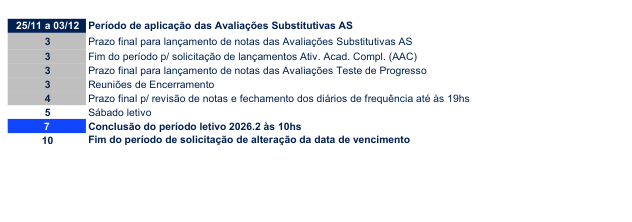

In [27]:
with pymupdf.open(arquivo_calendario) as documento:
    pagina = documento[0]
    largura = pagina.rect.width
    altura = pagina.rect.height

    recorte_dezembro = pymupdf.Rect(
        largura * 0.575,
        altura * 0.535,
        largura * 0.95,
        altura * 0.72,
    )

    imagem = pagina.get_pixmap(
        matrix=pymupdf.Matrix(2, 2),
        clip=recorte_dezembro,
    )
    texto_dezembro = pagina.get_text(clip=recorte_dezembro)

display(Image(data=imagem.tobytes("png")))

display(HTML(
    '<pre style="white-space: pre-wrap;">'
    + escape(texto_dezembro)
    + '</pre>'
))

In [28]:
textos_por_mes = {
    "julho": texto_julho,
    "agosto": texto_agosto,
    "setembro": texto_setembro,
    "outubro": texto_outubro,
    "novembro": texto_novembro,
    "dezembro": texto_dezembro,
}

registros_calendario = []

for mes, texto_mes in textos_por_mes.items():
    registros_calendario.append({
        "arquivo": arquivo_calendario.name,
        "pagina": 1,
        "mes": mes,
        "ano": 2026,
        "semestre": "2026.2",
        "texto": texto_mes,
        "sem_texto": not texto_mes.strip(),
    })

for registro in registros_calendario:
    quantidade = len(registro["texto"].strip())
    print(f"{registro['mes'].capitalize()}: {quantidade} caracteres")

Julho: 736 caracteres
Agosto: 389 caracteres
Setembro: 789 caracteres
Outubro: 347 caracteres
Novembro: 540 caracteres
Dezembro: 524 caracteres


In [29]:
from bs4 import BeautifulSoup

arquivo_html = raiz / "data" / "raw" / "html" / "05.html"

html = arquivo_html.read_text(encoding="utf-8")
sopa = BeautifulSoup(html, "html.parser")

print("Arquivo:", arquivo_html.name)
print("Título:", sopa.title.get_text(strip=True) if sopa.title else "Sem título")

for tag in ["main", "article"]:
    elementos = sopa.find_all(tag)
    print(f"\nElementos <{tag}> encontrados: {len(elementos)}")

    for numero, elemento in enumerate(elementos, start=1):
        texto_elemento = elemento.get_text(" ", strip=True)
        print(f"  Elemento {numero}: {len(texto_elemento)} caracteres")
        print("  Prévia:", texto_elemento[:500])

Arquivo: 05.html
Título: Guia Completo do Estudante Ibmec - Acesso e Primeiros Passos

Elementos <main> encontrados: 1
  Elemento 1: 0 caracteres
  Prévia: 

Elementos <article> encontrados: 0


In [30]:
elementos = sopa.find_all(["h1", "h2", "h3", "p"])

print("Títulos e parágrafos encontrados:", len(elementos))

for elemento in elementos[:20]:
    texto_elemento = elemento.get_text(" ", strip=True)

    if texto_elemento:
        print(f"<{elemento.name}> {texto_elemento}")

Títulos e parágrafos encontrados: 42
<p> Blog Ibmec Aluno Página atual
<h1> Guia do Estudante
<p> Tempo de leitura
<p> 7 minutos
<p> Atualizado em
<p> 16/07/2026
<h2> Introdução
<p> Acabou de ingressar em uma graduação do Ibmec? Seja bem-vindo calouro!
<p> Neste Guia do Estudante você irá encontrar tudo que precisa para iniciar sua jornada acadêmica da melhor forma, com links úteis, detalhes sobre acessos, passo a passo para fazer sua carteirinha de estudante e muito mais!
<h2> Sou calouro Ibmec, e agora?
<p> Antes de mais nada, parabéns, agora você faz parte de uma das principais instituições de ensino superior do país.
<p> Para acessar os ambientes online do Ibmec e as ferramentas disponibilizadas aos nossos alunos, como o pacote Office 365, é necessário utilizar seu e-mail institucional de estudante, que é gerado automaticamente na confirmação da sua matrícula.
<p> Com o e-mail pronto, você já pode acessar o SIA (Sistema de Informações Acadêmicas) para encontrar tudo que precisa, co

In [31]:
bloco_artigo = sopa.find(
    "div",
    attrs={"data-testid": "postagem-container"}
)

if bloco_artigo is None:
    raise ValueError("Bloco do artigo não encontrado.")

texto_artigo = bloco_artigo.get_text("\n", strip=True)

print("Caracteres extraídos:", len(texto_artigo))

display(HTML(
    '<pre style="white-space: pre-wrap; max-height: 500px; overflow-y: auto;">'
    + escape(texto_artigo)
    + '</pre>'
))

Caracteres extraídos: 5902


In [32]:
from urllib.parse import urljoin

url_fonte = "https://www.ibmec.br/blog/aluno/guia-do-estudante"
links_artigo = []

for link in bloco_artigo.find_all("a", href=True):
    links_artigo.append({
        "texto": link.get_text(" ", strip=True),
        "url": urljoin(url_fonte, link["href"]),
    })

print("Links encontrados:", len(links_artigo))

for link in links_artigo:
    print(f"\nTexto: {link['texto']}")
    print(f"URL: {link['url']}")

Links encontrados: 14

Texto: Portal SIA
URL: https://sia.ibmec.br/sianet/logon

Texto: Sala de Aula Virtual
URL: https://estudante.ibmec.br

Texto: baixar o Office 365 gratuitamente
URL: http://www.office.com/GetOffice365

Texto: Unidades Ibmec
URL: https://www.ibmec.br/o-ibmec/unidades

Texto: Ibmec Vagas
URL: https://jobzi.com/edu/ibmecvagas

Texto: Manual do Aluno
URL: https://d1v1kp8opafsrk.cloudfront.net/ibmec/manuais/manuadoaluno/GradManualAlunoIbmec.pdf

Texto: Aluno Ibmec BH
URL: https://www.ibmec.br/blog/tags/aluno-ibmec-bh

Texto: Aluno Ibmec RJ
URL: https://www.ibmec.br/blog/tags/aluno-ibmec-rj

Texto: Aluno Ibmec DF
URL: https://www.ibmec.br/blog/tags/aluno-ibmec-df

Texto: Aluno Ibmec SP
URL: https://www.ibmec.br/blog/tags/aluno-ibmec-sp

Texto: 
URL: https://api.whatsapp.com/send?text=%2Fblog%2Faluno%2Fguia-do-estudante

Texto: 
URL: https://www.facebook.com/sharer/sharer.php?u=%2Fblog%2Faluno%2Fguia-do-estudante

Texto: 
URL: https://twitter.com/intent/tweet?url=%2Fblog

In [33]:
container = bloco_artigo.find(
    "div", attrs={"data-lift": "lft-grid-content"}
)

secoes_html = [
    bloco
    for bloco in container.find_all("div", recursive=False)
    if bloco.find(["h2", "h3"])
]

links_conteudo = [
    {
        "texto": link.get_text(" ", strip=True),
        "url": urljoin(url_fonte, link["href"]),
    }
    for secao in secoes_html
    for link in secao.find_all("a", href=True)
]

print("Seções selecionadas:", len(secoes_html))
print("Links do conteúdo:", len(links_conteudo))

for link in links_conteudo:
    print(f"{link['texto']}: {link['url']}")

Seções selecionadas: 10
Links do conteúdo: 6
Portal SIA: https://sia.ibmec.br/sianet/logon
Sala de Aula Virtual: https://estudante.ibmec.br
baixar o Office 365 gratuitamente: http://www.office.com/GetOffice365
Unidades Ibmec: https://www.ibmec.br/o-ibmec/unidades
Ibmec Vagas: https://jobzi.com/edu/ibmecvagas
Manual do Aluno: https://d1v1kp8opafsrk.cloudfront.net/ibmec/manuais/manuadoaluno/GradManualAlunoIbmec.pdf


In [34]:
partes_texto = []

for secao in secoes_html:
    for elemento in secao.find_all(["h2", "h3", "p"]):
        texto_elemento = elemento.get_text(" ", strip=True)
        texto_elemento = " ".join(texto_elemento.split())

        if texto_elemento:
            partes_texto.append(texto_elemento)

texto_html_limpo = "\n\n".join(partes_texto)

display(HTML(
    '<pre style="white-space: pre-wrap; max-height: 500px; overflow-y: auto;">'
    + escape(texto_html_limpo)
    + '</pre>'
))

In [35]:
partes_texto = []

for secao in secoes_html:
    copia = BeautifulSoup(str(secao), "html.parser")

    # Remove as marcações internas, preservando seu texto.
    for tag in copia.find_all(["a", "span", "strong", "b", "em", "i", "u"]):
        tag.unwrap()

    copia.smooth()

    linhas = [
        " ".join(linha.split())
        for linha in copia.get_text("\n", strip=True).splitlines()
        if linha.strip()
    ]

    partes_texto.append("\n\n".join(linhas))

texto_html_limpo = "\n\n".join(partes_texto)

display(HTML(
    '<pre style="white-space: pre-wrap; max-height: 500px; overflow-y: auto;">'
    + escape(texto_html_limpo)
    + '</pre>'
))

In [36]:
registro_html_05 = {
    "arquivo": arquivo_html.name,
    "titulo": sopa.h1.get_text(" ", strip=True),
    "url": url_fonte,
    "data_atualizacao": "2026-07-16",
    "texto": texto_html_limpo,
    "links": links_conteudo,
}

print("Arquivo:", registro_html_05["arquivo"])
print("Título:", registro_html_05["titulo"])
print("Atualização:", registro_html_05["data_atualizacao"])
print("Caracteres:", len(registro_html_05["texto"]))
print("Links:", len(registro_html_05["links"]))

Arquivo: 05.html
Título: Guia do Estudante
Atualização: 2026-07-16
Caracteres: 5850
Links: 6


In [37]:
arquivo_html_06 = raiz / "data" / "raw" / "html" / "06.html"

sopa_06 = BeautifulSoup(
    arquivo_html_06.read_text(encoding="utf-8"),
    "html.parser",
)

print("Arquivo:", arquivo_html_06.name)
print(
    "Título:",
    sopa_06.title.get_text(" ", strip=True)
    if sopa_06.title else "Sem título"
)

for tag in ["main", "article", "form"]:
    print(f"Elementos <{tag}>:", len(sopa_06.find_all(tag)))

print("\nTítulos encontrados:")
for elemento in sopa_06.find_all(["h1", "h2", "h3", "h4"]):
    print(elemento.get_text(" ", strip=True))

Arquivo: 06.html
Título: FAQ
Elementos <main>: 0
Elementos <article>: 0
Elementos <form>: 0

Títulos encontrados:
FAQ - Login SIA aluno
01. Como realizar meu primeiro acesso?
02. Esqueci minha matrícula. O que fazer?
03. Esqueci/quero alterar minha senha. O que fazer?
04. Meu acesso ainda não foi liberado. Como prosseguir?


In [38]:
resumo_html = []

for arquivo in sorted((raiz / "data" / "raw" / "html").glob("*.html")):
    if arquivo.name == "05.html":
        continue

    pagina_html = BeautifulSoup(
        arquivo.read_text(encoding="utf-8"),
        "html.parser",
    )

    postagem = pagina_html.find(
        "div", attrs={"data-testid": "postagem-container"}
    )

    resumo_html.append({
        "arquivo": arquivo.name,
        "titulo": (
            pagina_html.title.get_text(" ", strip=True)
            if pagina_html.title else "Sem título"
        ),
        "postagem": postagem is not None,
        "main": len(pagina_html.find_all("main")),
        "article": len(pagina_html.find_all("article")),
        "caracteres": len(pagina_html.get_text(" ", strip=True)),
    })

for item in resumo_html:
    print(
        f"{item['arquivo']} | postagem={item['postagem']} | "
        f"main={item['main']} | article={item['article']} | "
        f"{item['caracteres']} caracteres"
    )
    print(f"  {item['titulo']}")

06.html | postagem=False | main=0 | article=0 | 5701 caracteres
  FAQ
07.html | postagem=True | main=1 | article=0 | 2796 caracteres
  Blog Ibmec | Educação de Qualidade Internacional
08.html | postagem=True | main=1 | article=0 | 3424 caracteres
  Guia Completo do Estágio no Ibmec: Tudo o que Você Precisa Saber | Blog Ibmec
09.html | postagem=False | main=1 | article=0 | 3954 caracteres
  Biblioteca: Conheça o acervo e biblioteca digital  | Ibmec
10.html | postagem=True | main=1 | article=0 | 1416 caracteres
  Minha Biblioteca Ibmec: 15 Mil E-books Gratuitos para Alunos | Blog Ibmec
11.html | postagem=True | main=1 | article=0 | 1642 caracteres
  Biblioteca Ibmec: Atendimento Personalizado para Melhorar sua Experiência | Blog Ibmec
12.html | postagem=False | main=1 | article=0 | 2707 caracteres
  Carreiras: Desenvolva suas skills para o mercado de trabalho | Ibmec
13.html | postagem=True | main=1 | article=0 | 2923 caracteres
  Blog Ibmec | Educação de Qualidade Internacional
14.html 

In [39]:
previas_blog = []

for item in resumo_html:
    if not item["postagem"]:
        continue

    arquivo = raiz / "data" / "raw" / "html" / item["arquivo"]
    pagina_html = BeautifulSoup(
        arquivo.read_text(encoding="utf-8"),
        "html.parser",
    )

    postagem = pagina_html.find(
        "div", attrs={"data-testid": "postagem-container"}
    )
    container = postagem.find(
        "div", attrs={"data-lift": "lft-grid-content"}
    )

    blocos = [
        bloco
        for bloco in container.find_all("div", recursive=False)
        if bloco.select_one("div.line-break") is not None
        or bloco.find(["h2", "h3"]) is not None
    ]

    texto = "\n\n".join(
        bloco.get_text(" ", strip=True)
        for bloco in blocos
    )

    previas_blog.append({
        "arquivo": arquivo.name,
        "titulo": pagina_html.h1.get_text(" ", strip=True),
        "texto": texto,
        "blocos": len(blocos),
    })

for previa in previas_blog:
    print(
        f"{previa['arquivo']} | {previa['blocos']} blocos | "
        f"{len(previa['texto'])} caracteres"
    )
    print(f"  Início: {previa['texto'][:100]}")
    print(f"  Final: {previa['texto'][-100:]}\n")

07.html | 5 blocos | 2468 caracteres
  Início: Introdução O estágio é uma etapa fundamental na formação acadêmica e profissional dos estudantes. Pa
  Final: ões pelo SIA. Em caso de dúvidas, procure a secretaria da sua unidade. Quem faz o futuro, faz Ibmec!

08.html | 2 blocos | 3050 caracteres
  Início: Introdução O estágio é um passo essencial para quem deseja se preparar para os desafios do mercado d
  Final: ssa etapa essencial para o seu futuro profissional! Saiba mais conferindo o manual abaixo: Ibmec-se!

10.html | 2 blocos | 1093 caracteres
  Início: Introdução A Minha Biblioteca é uma das principais plataformas digitais de livros acadêmicos do país
  Final: u.br Ibmec DF: bibliotecadf@ibmec.edu.br Ibmec BH: bibliotecabh@ibmec.edu.br WhatsApp: 0800 880 6771

11.html | 2 blocos | 1292 caracteres
  Início: Introdução Com o intuito de proporcionar uma experiência ainda mais enriquecedora para nossos estuda
  Final: e livro
13: Suspensão
14: Voltar ao Menu Inicial
15: Encerrar Conv

In [40]:
print("Páginas de blog processadas:", len(previas_blog))

for previa in previas_blog:
    if previa["arquivo"] in {"11.html", "14.html", "18.html"}:
        print(f"\n{previa['arquivo']} — {previa['titulo']}")

        display(HTML(
            '<pre style="white-space: pre-wrap; '
            'max-height: 400px; overflow-y: auto;">'
            + escape(previa["texto"])
            + '</pre>'
        ))

Páginas de blog processadas: 8

11.html — Biblioteca Ibmec | Agora o atendimento ficou ainda mais personalizado



14.html — Colação de Grau Ibmec | Tudo o que você precisa saber para colar grau no tempo regular



18.html — Você sabe o que é uma Atividade Complementar (AAC)?


In [41]:
for item in resumo_html:
    if item["postagem"]:
        continue

    arquivo = raiz / "data" / "raw" / "html" / item["arquivo"]
    pagina_html = BeautifulSoup(
        arquivo.read_text(encoding="utf-8"),
        "html.parser",
    )

    corpo = pagina_html.body
    texto_previa = corpo.get_text("\n", strip=True) if corpo else ""

    print(f"\n{arquivo.name} — {item['titulo']}")

    display(HTML(
        '<pre style="white-space: pre-wrap; '
        'max-height: 300px; overflow-y: auto;">'
        + escape(texto_previa)
        + '</pre>'
    ))


06.html — FAQ



09.html — Biblioteca: Conheça o acervo e biblioteca digital  | Ibmec



12.html — Carreiras: Desenvolva suas skills para o mercado de trabalho | Ibmec



15.html — Curso Ciência de Dados com a nota do ENEM | Ibmec



16.html — Informações Acadêmicas: Confira os documentos regulatórios | Ibmec


In [42]:
previas_institucionais = []

for nome in ["09.html", "12.html", "15.html", "16.html"]:
    arquivo = raiz / "data" / "raw" / "html" / nome
    pagina_html = BeautifulSoup(
        arquivo.read_text(encoding="utf-8"),
        "html.parser",
    )

    principal = pagina_html.find("main")
    texto = principal.get_text("\n", strip=True) if principal else ""

    previas_institucionais.append({
        "arquivo": nome,
        "texto": texto,
    })

    print(f"\n{nome} — {len(texto)} caracteres")

    display(HTML(
        '<pre style="white-space: pre-wrap; '
        'max-height: 300px; overflow-y: auto;">'
        + escape(texto)
        + '</pre>'
    ))


09.html — 1427 caracteres



12.html — 170 caracteres



15.html — 0 caracteres



16.html — 91 caracteres


In [43]:
for nome in ["12.html", "15.html", "16.html"]:
    arquivo = raiz / "data" / "raw" / "html" / nome
    pagina_html = BeautifulSoup(
        arquivo.read_text(encoding="utf-8"),
        "html.parser",
    )
    principal = pagina_html.find("main")

    print(f"\n{nome}")

    if principal is not None:
        for link in principal.find_all("a", href=True):
            print(
                "Link:",
                link.get_text(" ", strip=True),
                "→", link["href"]
            )

        for iframe in principal.find_all("iframe"):
            print("Conteúdo incorporado:", iframe.get("src"))

    print("Scripts na página:", len(pagina_html.find_all("script")))


12.html
Link: Início → /
Scripts na página: 32

15.html
Scripts na página: 30

16.html
Link: O Ibmec → /o-ibmec
Scripts na página: 31


In [44]:
import json

dados_paginas = {}

for nome in ["12.html", "15.html", "16.html"]:
    arquivo = raiz / "data" / "raw" / "html" / nome
    pagina_html = BeautifulSoup(
        arquivo.read_text(encoding="utf-8"),
        "html.parser",
    )

    script = pagina_html.find("script", id="__NEXT_DATA__")
    dados = json.loads(script.string)

    chave = "course" if nome == "15.html" else "convencimento"
    blocos = dados["props"]["pageProps"][chave]["body"]
    dados_paginas[nome] = blocos

    print(f"\n{nome}: {len(blocos)} blocos")
    for bloco in blocos:
        titulo = bloco.get("title")
        if titulo:
            print("  -", titulo)


12.html: 13 blocos
  - Ibmec Carreiras
  - Como o Ibmec ajuda na empregabilidade?
  - O que você encontra no Ibmec Carreiras
  - Como a CASA apoia você na prática
  - Projetos da CASA para apoiar sua jornada acadêmica
  - Conheça o Ibmec Carreiras e CASA
  - Conheça a experiência de alunos e Alumni
  - Construa sua carreira com o Ibmec
  - Perguntas frequentes
  - Contatos

15.html: 12 blocos
  - Ciência de Dados e Inteligência Artificial
  - Diferenciais do Ibmec
  - Nossas unidades
  - O que você vai aprender
  - Perfil do Profissional de Ciência de Dados e IA
  - Áreas de Atuação no Mercado de Ciência de Dados e IA
  - Reconhecimentos
  - Transformamos a vida de pessoas como você
  - Formas de ingresso
  - {'text': None, 'type': 'h2'}
  - Perguntas frequentes

16.html: 3 blocos
  - Informações Acadêmicas
  - Acesse as informações de cada unidade: 


In [45]:
campos_textuais = {
    "title", "text", "description", "detail",
    "templateTitle", "templateDescription",
    "templateSubtitle", "templateSubtitleDescription",
    "contentSection", "cardDescription",
    "titleItem", "descriptionItem",
    "subtitle", "subTitle", "descriptionText",
}

def coletar_textos(valor, caminho=""):
    resultados = []

    if isinstance(valor, dict):
        for chave, conteudo in valor.items():
            local = f"{caminho}.{chave}"

            if (
                chave in campos_textuais
                and isinstance(conteudo, str)
                and conteudo.strip()
            ):
                resultados.append({
                    "caminho": local,
                    "texto": conteudo.strip(),
                })

            elif isinstance(conteudo, (dict, list)):
                resultados.extend(coletar_textos(conteudo, local))

    elif isinstance(valor, list):
        for indice, conteudo in enumerate(valor):
            resultados.extend(
                coletar_textos(conteudo, f"{caminho}[{indice}]")
            )

    return resultados


textos_incorporados = {
    nome: coletar_textos(blocos, "body")
    for nome, blocos in dados_paginas.items()
}

for nome, campos in textos_incorporados.items():
    caracteres = sum(len(campo["texto"]) for campo in campos)
    print(f"{nome}: {len(campos)} campos | {caracteres} caracteres")

12.html: 89 campos | 8582 caracteres
15.html: 94 campos | 9518 caracteres
16.html: 11 campos | 2322 caracteres


In [46]:
for indice, bloco in enumerate(dados_paginas["12.html"]):
    if bloco.get("title") not in {"Perguntas frequentes", "Contatos"}:
        continue

    print(f"\n12.html — {bloco['title']}")

    campos = coletar_textos(bloco, f"body[{indice}]")

    texto_revisao = "\n\n".join(
        f"{campo['caminho']}\n{campo['texto']}"
        for campo in campos
    )

    display(HTML(
        '<pre style="white-space: pre-wrap; '
        'max-height: 400px; overflow-y: auto;">'
        + escape(texto_revisao)
        + '</pre>'
    ))


12.html — Perguntas frequentes



12.html — Contatos


In [47]:
faq_carreiras = []

for indice_bloco, bloco in enumerate(dados_paginas["12.html"]):
    if bloco.get("title") != "Perguntas frequentes":
        continue

    for indice_card, card in enumerate(bloco.get("cards", [])):
        faq_carreiras.append({
            "arquivo": "12.html",
            "caminho": f"body[{indice_bloco}].cards[{indice_card}]",
            "pergunta": card.get("title", ""),
            "resposta": card.get("detail", ""),
        })

print("Pares extraídos:", len(faq_carreiras))

for registro in faq_carreiras:
    status = "OK" if registro["pergunta"] and registro["resposta"] else "REVISAR"
    print(f"{status} — {registro['pergunta']}")

Pares extraídos: 6
OK — O que é o Ibmec Carreiras?
OK — Quem pode utilizar o Ibmec Carreiras?
OK — Como o Ibmec ajuda na busca por estágio?
OK — O que é a CASA?
OK — Como a CASA apoia os estudantes?
OK — Alumni também pode utilizar os serviços?


In [49]:
arquivo = raiz / "data" / "raw" / "html" / "06.html"
pagina_html = BeautifulSoup(
    arquivo.read_text(encoding="utf-8"),
    "html.parser",
)

faq_sia = []

for secao in pagina_html.find_all("section"):
    titulo = secao.find("h1")

    if titulo is None:
        continue

    faq_sia.append({
        "arquivo": arquivo.name,
        "secao_id": secao.get("id"),
        "pergunta": titulo.get_text(" ", strip=True),
        "texto": secao.get_text("\n", strip=True),
        "status": "revisar_atualidade",
    })

print("Seções extraídas:", len(faq_sia))

for registro in faq_sia:
    print(f"{registro['secao_id']} — {registro['pergunta']}")

Seções extraídas: 4
primeira — 01. Como realizar meu primeiro acesso?
segunda — 02. Esqueci minha matrícula. O que fazer?
terceira — 03. Esqueci/quero alterar minha senha. O que fazer?
quarta — 04. Meu acesso ainda não foi liberado. Como prosseguir?


In [50]:
print("PDFs")
print("  Manual:", len(paginas_manual), "páginas")
print("  Guia do Aluno:", len(paginas_guia), "páginas")
print("  Guia do Calouro:", len(paginas_calouro), "páginas")
print("  Calendário:", len(registros_calendario), "registros mensais")

print("\nHTML")
print("  Guia do Estudante:", registro_html_05["arquivo"])
print("  Outros blogs:", len(previas_blog), "prévias")
print("  Institucionais:", len(previas_institucionais), "prévias")
print("  Dados incorporados:", len(textos_incorporados), "arquivos")
print("  FAQ Carreiras/CASA:", len(faq_carreiras), "pares")
print("  FAQ SIA:", len(faq_sia), "seções")

PDFs
  Manual: 49 páginas
  Guia do Aluno: 12 páginas
  Guia do Calouro: 49 páginas
  Calendário: 6 registros mensais

HTML
  Guia do Estudante: 05.html
  Outros blogs: 8 prévias
  Institucionais: 4 prévias
  Dados incorporados: 3 arquivos
  FAQ Carreiras/CASA: 6 pares
  FAQ SIA: 4 seções


In [51]:
import csv

registros_pdf = []

fontes = (
    paginas_manual
    + paginas_guia
    + paginas_calouro
    + registros_calendario
)

for registro in fontes:
    sem_texto = not registro["texto"].strip()

    if sem_texto:
        observacao = "Sem texto extraível; manter para revisão."
    elif registro.get("mes"):
        observacao = "Recorte mensal conferido visualmente."
    else:
        observacao = "Documento revisado por amostragem, não página a página."

    registros_pdf.append({
        "arquivo": registro["arquivo"],
        "pagina": registro["pagina"],
        "mes": registro.get("mes", ""),
        "ano": registro.get("ano", ""),
        "semestre": registro.get("semestre", ""),
        "texto": registro["texto"],
        "sem_texto": sem_texto,
        "observacao": observacao,
    })

destino = raiz / "data" / "processed" / "textos_pdfs.csv"
destino.parent.mkdir(parents=True, exist_ok=True)

with destino.open("x", encoding="utf-8-sig", newline="") as arquivo:
    escritor = csv.DictWriter(
        arquivo,
        fieldnames=list(registros_pdf[0]),
        delimiter=";",
    )
    escritor.writeheader()
    escritor.writerows(registros_pdf)

print("Arquivo salvo:", destino)
print("Registros:", len(registros_pdf))
print("Sem texto:", sum(r["sem_texto"] for r in registros_pdf))

Arquivo salvo: /Users/hugofilho/Documents/projeto-pln/data/processed/textos_pdfs.csv
Registros: 116
Sem texto: 2


In [52]:
with destino.open("r", encoding="utf-8-sig", newline="") as arquivo:
    registros_lidos = list(csv.DictReader(arquivo, delimiter=";"))

registros_esperados = [
    {chave: str(valor) for chave, valor in registro.items()}
    for registro in registros_pdf
]

assert registros_lidos == registros_esperados, (
    "O conteúdo lido difere dos registros originais."
)

print("Gravação conferida: todos os campos foram preservados.")
print("Registros recuperados:", len(registros_lidos))

Gravação conferida: todos os campos foram preservados.
Registros recuperados: 116


In [53]:
conteudos_html = {
    "05.html": registro_html_05["texto"],
}

# Oito páginas de blog.
for previa in previas_blog:
    conteudos_html[previa["arquivo"]] = previa["texto"]

# Biblioteca: conteúdo selecionado em <main>.
for previa in previas_institucionais:
    if previa["arquivo"] == "09.html":
        conteudos_html["09.html"] = previa["texto"]

# Carreiras, curso e informações acadêmicas:
# usar os dados incorporados, que contêm mais conteúdo.
for nome, campos in textos_incorporados.items():
    conteudos_html[nome] = "\n\n".join(
        campo["texto"] for campo in campos
    )

# FAQ do SIA: quatro seções, sem o menu de navegação.
conteudos_html["06.html"] = "\n\n".join(
    secao["texto"] for secao in faq_sia
)

assert len(conteudos_html) == 14, "Esperávamos 14 arquivos HTML."

for nome, texto_extraido in sorted(conteudos_html.items()):
    status = "COM TEXTO" if texto_extraido.strip() else "REVISAR: VAZIO"
    print(f"{nome} | {len(texto_extraido)} caracteres | {status}")

05.html | 5850 caracteres | COM TEXTO
06.html | 5503 caracteres | COM TEXTO
07.html | 2468 caracteres | COM TEXTO
08.html | 3050 caracteres | COM TEXTO
09.html | 1427 caracteres | COM TEXTO
10.html | 1093 caracteres | COM TEXTO
11.html | 1292 caracteres | COM TEXTO
12.html | 8758 caracteres | COM TEXTO
13.html | 2601 caracteres | COM TEXTO
14.html | 5000 caracteres | COM TEXTO
15.html | 9704 caracteres | COM TEXTO
16.html | 2342 caracteres | COM TEXTO
17.html | 1930 caracteres | COM TEXTO
18.html | 704 caracteres | COM TEXTO


In [54]:
urls_da_coleta = {
    "06.html": "https://sia.ibmec.br/sianet/Content/ibmec/SiteNovo/dist/html/main-ibmec.html",
    "07.html": "https://www.ibmec.br/blog/graduacao/entrega-documentacao-estagio-pelo-SIA",
    "13.html": "https://www.ibmec.br/blog/aluno/renovacao-e-pre-matricula-26.2",
}

pendencias = {
    "06.html": "Conferir atualidade das instruções de acesso e senha.",
    "12.html": "Distinguir graduação, pós-graduação e unidades nos serviços.",
    "14.html": "Contém prazos encerrados de maio e junho de 2026.",
    "15.html": "Página de divulgação; conferir unidade e modalidade.",
    "16.html": "Índice de documentos; avaliar uso apenas como referência.",
}

registros_html = []

for nome, texto_extraido in sorted(conteudos_html.items()):
    arquivo = raiz / "data" / "raw" / "html" / nome
    pagina_html = BeautifulSoup(
        arquivo.read_text(encoding="utf-8"),
        "html.parser",
    )

    canonical = pagina_html.find("link", rel="canonical")
    url = (
        canonical.get("href", "").strip()
        if canonical else urls_da_coleta.get(nome, "")
    )

    titulo = pagina_html.find("h1") or pagina_html.title

    registros_html.append({
        "arquivo": nome,
        "titulo": titulo.get_text(" ", strip=True) if titulo else "",
        "url": url,
        "texto": texto_extraido,
        "status": "pendente_revisao",
        "observacao": pendencias.get(
            nome, "Conferir conteúdo, abrangência e sobreposição com outras fontes."
        ),
    })

print("Registros preparados:", len(registros_html))
print("Com URL:", sum(bool(r["url"]) for r in registros_html))
print("Com título:", sum(bool(r["titulo"]) for r in registros_html))

Registros preparados: 14
Com URL: 14
Com título: 14


In [55]:
destino_html = raiz / "data" / "processed" / "textos_html.csv"

with destino_html.open("x", encoding="utf-8-sig", newline="") as arquivo:
    escritor = csv.DictWriter(
        arquivo,
        fieldnames=list(registros_html[0]),
        delimiter=";",
    )
    escritor.writeheader()
    escritor.writerows(registros_html)

with destino_html.open("r", encoding="utf-8-sig", newline="") as arquivo:
    html_recuperados = list(csv.DictReader(arquivo, delimiter=";"))

assert html_recuperados == registros_html, (
    "O conteúdo recuperado difere dos registros originais."
)

print("Arquivo salvo:", destino_html)
print("Registros recuperados:", len(html_recuperados))
print("Gravação conferida: todos os campos foram preservados.")

Arquivo salvo: /Users/hugofilho/Documents/projeto-pln/data/processed/textos_html.csv
Registros recuperados: 14
Gravação conferida: todos os campos foram preservados.
